# From LLM to Farm Operations Agent: Reinforcement Learning with GRPO

**Practical workshop · Qwen2.5-0.5B-Instruct + GRPO + LoRA · Hugging Face TRL**

> *Can we improve an LLM's ability to investigate farm operations by rewarding it for choosing the correct tools and using the returned data?*

⚠️ **All data in this notebook is synthetic dummy data.** Barns, cameras, schedules and events are generated from a random seed.

| Section | Topic |
|---|---|
| 0 | Setup + **start GRPO training in the background** |
| 1 | Why RL? · How GRPO works · the bigger picture *(training runs meanwhile)* |
| 2 | The farm environment (tools + simulated data) |
| 3 | Training dataset |
| 4 | Baseline + GRPO signal check |
| 5 | Reward functions |
| 6 | GRPO training results |
| 7 | Evaluate the trained policy |
| 8 | Challenge: reward hacking & multi-step agent |
| 9 | Metrics summary |

Code lives in `src/farm_grpo/` (one module per section); the notebook only orchestrates.
`workshop.ipynb` uses English requests, `workshop_uk.ipynb` the same workshop with Ukrainian requests.

**This version uses Ukrainian requests.** Only the user requests in the dataset (and the multi-step questions) are Ukrainian.
Tool names, argument keys, the system prompt and the labels stay English / ISO, as with most real APIs.
The model is trained and evaluated on Ukrainian requests. All outputs and metrics are kept separate in `outputs/uk/`.

---
# Section 0 · Setup

In [1]:
%load_ext autoreload
%autoreload 2

LANG = "uk"   # language of the dataset requests: "en" or "uk"

import json, time, os
import torch, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)

from farm_grpo.config import get_config
cfg = get_config(lang=LANG)   # lang="uk" -> data/uk/ and outputs/uk/ (separate from English)

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
pd.Series(cfg.to_dict(), name="config").to_frame()

torch 2.14.1+cu130 | CUDA: True | NVIDIA GeForce RTX 3090


,config
model_id,Qwen/Qwen2.5-0.5B-Instruct
seed,42
lang,uk
n_train,240
n_val,40
n_test,80
lora_r,8
lora_alpha,16
lora_dropout,0.05
lora_target_modules,"[q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj]"


In [2]:
# ---- Training mode ------------------------------------------------------------------------
TRAINING_MODE = "background"   # "background": start both GRPO runs NOW, they train while we work through Sections 1-5
                               # "inline":     train inside the Section 6 / 8 cells (blocks the notebook)
                               # "pretrained": no training at all, load the saved checkpoints
LIVE_STEPS, HACK_STEPS = cfg.live_max_steps, 60

CKPT = cfg.data_dir / "checkpoints"   # saved checkpoints from a dry run (never overwritten)
if TRAINING_MODE == "pretrained" and CKPT.exists():
    LIVE_DIR, HACK_DIR = CKPT / "live_run", CKPT / "hack_many_args"
else:
    LIVE_DIR, HACK_DIR = cfg.live_run_dir, cfg.output_dir / "hack_many_args"
print(LANG, "|", TRAINING_MODE, "| live:", LIVE_DIR, "| hack:", HACK_DIR)

uk | background | live: /home/mudryi/phd_projects/grpo-farm-agent-workshop/outputs/uk/live_run | hack: /home/mudryi/phd_projects/grpo-farm-agent-workshop/outputs/uk/hack_many_args


### Start training now. We look at the result in Section 6.

Two GRPO runs start as **separate processes** on the GPU (with the reward functions from Section 5, `farm_grpo/rewards.py`):
* `live`: the real reward (format + tool + arguments), 100 steps
* `hack`: a deliberately bad reward (`many_args`), 60 steps, for Section 8

Run `status(lang=LANG)` any time to peek at progress.

In [3]:
from farm_grpo.background import start_runs, status, wait_for
if TRAINING_MODE == "background":
    start_runs(["live", "hack"], lang=LANG)
status(lang=LANG)

[live] started pid 138244  ->  outputs/uk/live_run  (log: outputs/uk/logs/live.log)
[hack] started pid 138245  ->  outputs/uk/hack_many_args  (log: outputs/uk/logs/hack.log)


,state,step,held-out success %,minutes since start
run,,,,
live,running,0/?,[],0.0
hack,running,0/?,[],0.0


---
# Section 1 · Why reinforcement learning? How GRPO works

## 1.1 Four questions to start

1. **What does next-token prediction actually optimize?**  The likelihood of the *training text*, not whether the answer works.
2. **What is the difference between predicting the correct action and maximizing success in an environment?**  Imitation vs. outcomes.
3. **Why doesn't supervised fine-tuning always solve that problem?**  SFT needs a perfect demonstration for every task, and it never sees its *own* mistakes.
4. **Can we teach an LLM from outcomes without a perfect example response for every task?**  Yes, if we can *score* a response. That score is the reward.

## 1.2 RL vocabulary, mapped to our farm agent

| RL term | In this workshop |
|---|---|
| **Policy** $\pi_\theta$ | Qwen2.5-0.5B (+ LoRA adapter) |
| **Action** | The generated JSON tool call |
| **Environment** | Simulated farm with 4 read-only tools |
| **Rollout** | Sampling a completion for a prompt |
| **Reward** | Python function scoring the completion |
| **Exploration** | Sampling at temperature 1.0 → varied completions |

> **Honest caveat: RL is not automatically better than SFT.** For one-step tool selection with reliable labels, SFT may be simpler and more effective.
> RL becomes attractive when the correct *sequence* of actions is unknown but **task success can be evaluated**.
> We use the single-step task because it trains in minutes, which makes it a good way to *learn the mechanics*.

## 1.3 GRPO: Group Relative Policy Optimization

For each prompt $q$ we sample a **group** of $G$ completions $o_1,\dots,o_G$, score each with the reward, and normalise **within the group**:

$$A_i = \frac{r_i - \operatorname{mean}(r_1,\ldots,r_G)}{\operatorname{std}(r_1,\ldots,r_G)}$$

* Completions better than their siblings get $A_i>0$ and become more likely. Worse ones get $A_i<0$.
* **No critic / value network** (unlike PPO). The group mean *is* the baseline, which saves memory and compute.
* The full objective adds a clipped policy-ratio update (like PPO) and optionally a KL penalty $\beta\,\mathrm{KL}(\pi_\theta\|\pi_\text{ref})$. We use $\beta=0$.
* **Limitations:** generation is expensive (G samples per prompt), the model can *hack* the reward, and **if every completion in a group gets the same reward then $A_i=0$, so there is no learning signal**.

mixed group (useful signal)    rewards=[1.0, 0.3, 1.0, -0.2]  advantages=[0.94, -0.44, 0.94, -1.43]
all correct (no signal)        rewards=[1.0, 1.0, 1.0, 1.0]  advantages=[0.0, 0.0, 0.0, 0.0]
all invalid (no signal)        rewards=[-0.2, -0.2, -0.2, -0.2]  advantages=[0.0, 0.0, 0.0, 0.0]


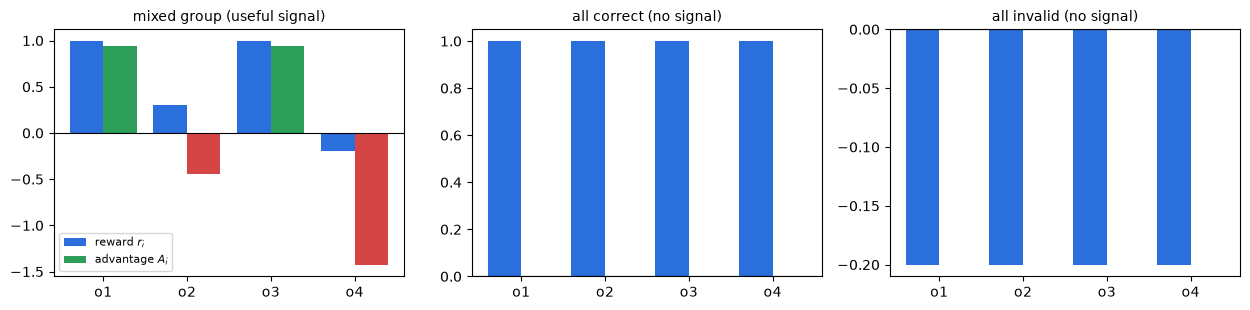

In [4]:
from farm_grpo.plotting import group_advantages, plot_advantages

groups = {
    "mixed group (useful signal)":   [1.0, 0.3, 1.0, -0.2],
    "all correct (no signal)":       [1.0, 1.0, 1.0, 1.0],
    "all invalid (no signal)":       [-0.2, -0.2, -0.2, -0.2],
}
for name, r in groups.items():
    print(f"{name:<30} rewards={r}  advantages={group_advantages(r).round(2).tolist()}")
plot_advantages(groups);

**What this plot shows:** in the mixed group the two correct answers get a positive advantage and the invalid one a strongly negative one,
so the update pushes probability towards the correct calls. In the all-correct and all-invalid groups every advantage is 0:
those prompts contribute **nothing** to the gradient, no matter how good or bad the answers are.

## 1.4 While the model trains: the bigger picture

**Where GRPO fits**

| Method | Learning signal | What you need | Known from |
|---|---|---|---|
| SFT | imitate demonstrations | a correct answer for every prompt | every instruct model |
| RLHF with PPO | reward model trained on human preferences, plus a learned critic | policy + reference + reward model + value model (4 networks) | InstructGPT / ChatGPT |
| DPO | offline preference pairs, no sampling, no reward model | (chosen, rejected) pairs | many open models |
| **GRPO** | **any reward you can compute**, online sampling, group mean as baseline | policy (+ optional reference for KL) | DeepSeekMath, DeepSeek-R1 |

**RL with verifiable rewards (RLVR).** When correctness can be *checked* (math answer, unit tests, a valid tool call), the reward is a program, not a learned model.
That is our setup. It is cheaper and harder to fool than a learned reward model, but **not impossible to hack** (Section 8).

**The DeepSeek-R1 story.** R1-Zero was trained with GRPO directly from a base model using only rule-based rewards (answer accuracy + output format).
Long step-by-step reasoning *emerged* without any reasoning demonstrations. Same mechanics as today, much bigger scale.

**Knobs you will see in TRL's `GRPOConfig`**
* `num_generations` (G): more samples give a better baseline but cost more generation.
* `beta`: KL penalty to a frozen reference model (0 = no reference model, saves memory).
* `loss_type` (`grpo`, `dr_grpo`, `dapo`; TRL 1.x defaults to `dapo`) and `scale_rewards` (divide by the group std or not; Dr. GRPO argues the std/length normalisation biases learning).
* `epsilon`: PPO-style clipping of the policy ratio.

**Cost reality.** Rollout *generation* dominates the time. Production setups generate with vLLM (`use_vllm=True`) and train with LoRA or many GPUs.

**Agentic RL.** Multi-turn tool use means the reward arrives only at the end, and you must decide which step deserved credit. TRL supports tool rollouts (`environment_factory`). See Section 8.2.

**Questions to think about:** Where in your work could you *verify* an outcome automatically? What would a cheating model do to your reward?

In [5]:
status(lang=LANG)   # peek at the background runs

,state,step,held-out success %,minutes since start
run,,,,
live,running,48/100,"[57.5, 77.5]",2.9
hack,running,36/60,"[57.5, 75.0]",2.9


---
# Section 2 · The farm environment

A simplified, **synthetic** dairy farm: 4 barns (A–D), 8 cameras (two per barn), a feed-pushing robot, a feed mixer wagon and a feeding plan.
"Today" in the simulation is fixed at **2026-03-10**, so labels are reproducible.

## 2.1 The tools (read-only)

In [6]:
from farm_grpo.environment import TOOL_SPECS, build_world, tool_spec_text, TODAY, CAMERAS
print(tool_spec_text())

- get_robot_events(barn_id, start_time, end_time): Feed-pushing robot visits in a barn TODAY within a time window.
    * barn_id: Barn letter, one of A, B, C, D
    * start_time: HH:MM (24h)
    * end_time: HH:MM (24h)
- get_mixer_events(barn_id, date): Arrival times of the feed-mixer wagon in a barn on a date.
    * barn_id: Barn letter, one of A, B, C, D
    * date: YYYY-MM-DD
- get_feeding_schedule(barn_id, date): PLANNED feed-push times for a barn on a date.
    * barn_id: Barn letter, one of A, B, C, D
    * date: YYYY-MM-DD
- get_camera_status(camera_id, date): Online/offline status and outage windows of a camera on a date.
    * camera_id: Camera number, integer 1-8
    * date: YYYY-MM-DD


## 2.2 The simulated world

In [7]:
world = build_world()
world.save(cfg.data_dir / "farm_world.json")

print("Feeding schedule (planned, every day):")
display(pd.DataFrame({b: world.schedules[b][TODAY.isoformat()] for b in "ABCD"}.items(),
                     columns=["barn", "planned_feed_push"]))
print("Robot events TODAY:")
display(pd.DataFrame([{"barn": b, **e} for b, evs in world.robot_events.items() for e in evs]))

Feeding schedule (planned, every day):


,barn,planned_feed_push
0,A,"[07:00, 10:00, 13:00, 16:00, 19:00]"
1,B,"[06:30, 09:30, 12:30, 15:30, 18:30]"
2,C,"[07:15, 11:15, 15:15, 19:15]"
3,D,"[08:00, 12:00, 16:00, 20:00]"


Robot events TODAY:


,barn,time,scheduled,delay_min
0,A,07:18,07:00,18
1,A,10:00,10:00,0
2,A,16:02,16:00,2
3,A,19:04,19:00,4
4,B,06:47,06:30,17
5,B,09:30,09:30,0
6,B,12:58,12:30,28
7,B,18:31,18:30,1
8,C,07:19,07:15,4
9,C,11:19,11:15,4


## 2.3 Calling tools by hand

In [8]:
print(world.execute("get_feeding_schedule", {"barn_id": "A", "date": "today"}))
print(world.execute("get_robot_events",     {"barn_id": "A", "start_time": "06:00", "end_time": "12:00"}))
print(world.execute("get_mixer_events",     {"barn_id": "B", "date": "yesterday"}))
print(world.execute("get_camera_status",    {"camera_id": 3, "date": "2026-03-09"}))
print(world.execute("get_robot_events",     {"barn_id": "Z", "start_time": "6"}))  # invalid -> error, never raises

{'barn_id': 'A', 'date': '2026-03-10', 'planned_feed_push': ['07:00', '10:00', '13:00', '16:00', '19:00']}
{'barn_id': 'A', 'date': '2026-03-10', 'window': ['06:00', '12:00'], 'events': [{'time': '07:18', 'type': 'feed_push'}, {'time': '10:00', 'type': 'feed_push'}]}
{'barn_id': 'B', 'date': '2026-03-09', 'arrivals': ['05:49', '13:47']}
{'camera_id': 3, 'barn_id': 'B', 'date': '2026-03-09', 'status': 'degraded', 'outages': [['22:10', '23:40']]}
{'error': "invalid arguments for get_robot_events: {'barn_id': 'Z', 'start_time': '6'}"}


## 2.4 The target workflow: *"Was the feed-pushing robot late in Barn A this morning?"*

A perfect (scripted) investigation needs **two** tool calls plus reasoning over the results:

In [9]:
from farm_grpo.agent import oracle_investigation
for step in oracle_investigation(world, "A"):
    print(json.dumps(step, ensure_ascii=False))

{"call": {"tool": "get_feeding_schedule", "arguments": {"barn_id": "A", "date": "2026-03-10"}}, "result": {"barn_id": "A", "date": "2026-03-10", "planned_feed_push": ["07:00", "10:00", "13:00", "16:00", "19:00"]}}
{"call": {"tool": "get_robot_events", "arguments": {"barn_id": "A", "start_time": "06:00", "end_time": "12:00"}}, "result": {"barn_id": "A", "date": "2026-03-10", "window": ["06:00", "12:00"], "events": [{"time": "07:18", "type": "feed_push"}, {"time": "10:00", "type": "feed_push"}]}}
{"final_answer": "Yes. Planned 07:00, robot arrived 07:18: 18 minutes late."}


For the **core exercise** we train only **one correct tool call with valid arguments**.
Single-step tool selection is much easier to train than a multi-turn agent that must execute tools, observe results and decide what to do next.
The full investigation returns in Section 8.

---
# Section 3 · Training dataset

Synthetic farm requests for 4 tools, with linguistic variation, **distractors** (mentions of other tools/barns) and unseen values.

**Crucial:** we split by **template family**, not by random shuffling. Each tool has 8 phrasing families:
5 → train, 1 → validation, 2 → test only. Barn **D** and cameras **7–8** never appear in training.
Otherwise near-duplicate sentences leak into the test set and accuracy looks artificially good.

In this version the requests are **Ukrainian**, with times and dates written in many ways: `07:00`, `7:00`, `7.30`, «7 ранку», «3 дня»,
«сьогодні», «вчора», «8 березня», `08.03.2026`… The labels (expected arguments) are always canonical: `HH:MM`, `YYYY-MM-DD`, barn letter, camera number.

In [10]:
from farm_grpo.dataset import generate_records, save_records, to_hf_dataset, TEMPLATES_BY_LANG, SPLIT_OF_TEMPLATE_INDEX
from farm_grpo.prompts import SYSTEM_PROMPT

records = generate_records(cfg.n_train, cfg.n_val, cfg.n_test, cfg.seed, lang=LANG)
save_records(records, cfg.data_dir)
print({k: len(v) for k, v in records.items()})

fam_split = pd.DataFrame([(tool, fam, split, tmpl) for tool, ts in TEMPLATES_BY_LANG[LANG].items()
                          for (fam, tmpl, _), split in zip(ts, SPLIT_OF_TEMPLATE_INDEX)],
                         columns=["tool", "family", "split", "template"])
fam_split

{'train': 240, 'val': 40, 'test': 80}


,tool,family,split,template
0,get_robot_events,robot_show,train,Покажи проходи робота в корівнику {barn} з {start} до {end}.
1,get_robot_events,robot_find,train,Знайди події робота в корівнику {barn} між {start} та {end}.
2,get_robot_events,robot_when,train,Коли робот-підштовхувач корму проходив корівником {barn} між {start} і {end}?
3,get_robot_events,robot_period,train,Чи підштовхував робот корм у корівнику {barn} {period}?
4,get_robot_events,robot_distract,train,"Забудь про міксер, мені потрібен журнал робота для корівника {barn} з {start} до {end}."
5,get_robot_events,robot_terse,val,активність робота корівник {barn} {start}-{end}
6,get_robot_events,robot_count,test,Скільки разів робот-підштовхувач працював у корівнику {barn} {period}?
7,get_robot_events,robot_distract2,test,Графік для корівника {other_barn} в нормі. Які проходи з підштовхування корму зробив робот у корівнику {barn} між {s...
8,get_mixer_events,mixer_when,train,Коли міксер приїхав у корівник {barn} {date}?
9,get_mixer_events,mixer_show,train,Покажи події міксера для корівника {barn} {date}.


In [11]:
# A few examples per split
for split in ["train", "test"]:
    print(f"===== {split} =====")
    for r in records[split][:6]:
        print(f"{r.question:<95} -> {r.expected_tool} {r.expected_args}")

===== train =====
Покажи події міксера для корівника B 08.03.2026.                                                -> get_mixer_events {"barn_id": "B", "date": "2026-03-08"}
Чи заїжджав кормозмішувач у корівник A 5 березня 2026 р.?                                       -> get_mixer_events {"barn_id": "A", "date": "2026-03-05"}
Коли має підштовхуватися корм у корівнику A 8 березня 2026 р.?                                  -> get_feeding_schedule {"barn_id": "A", "date": "2026-03-08"}
Чи заїжджав кормозмішувач у корівник B 2026-03-05?                                              -> get_mixer_events {"barn_id": "B", "date": "2026-03-05"}
Що каже графік годування для корівника B 8 березня 2026 р.?                                     -> get_feeding_schedule {"barn_id": "B", "date": "2026-03-08"}
Покажи події міксера для корівника A 10 березня.                                                -> get_mixer_events {"barn_id": "A", "date": "2026-03-10"}
===== test =====
О котрій міксер привіз свіж

In [12]:
# Leakage checks
fam = {s: {r.family for r in records[s]} for s in records}
assert not fam["train"] & fam["test"] and not fam["train"] & fam["val"], "template leakage!"
assert not {r.question for r in records["train"]} & {r.question for r in records["test"]}
print("No template-family or question leakage between splits ✔")

train_ds = to_hf_dataset(records["train"])
print(train_ds)
print("\nSystem prompt the model sees:\n" + "-" * 60 + "\n" + SYSTEM_PROMPT)

No template-family or question leakage between splits ✔
Dataset({
    features: ['id', 'split', 'family', 'question', 'expected_tool', 'expected_args', 'prompt'],
    num_rows: 240
})

System prompt the model sees:
------------------------------------------------------------
You are a farm-operations assistant for a dairy farm.
Today is 2026-03-10 (Tuesday). Day parts: morning = 06:00-12:00, afternoon = 12:00-18:00, evening = 18:00-22:00.

You can call exactly ONE of these read-only tools:
- get_robot_events(barn_id, start_time, end_time): Feed-pushing robot visits in a barn TODAY within a time window.
    * barn_id: Barn letter, one of A, B, C, D
    * start_time: HH:MM (24h)
    * end_time: HH:MM (24h)
- get_mixer_events(barn_id, date): Arrival times of the feed-mixer wagon in a barn on a date.
    * barn_id: Barn letter, one of A, B, C, D
    * date: YYYY-MM-DD
- get_feeding_schedule(barn_id, date): PLANNED feed-push times for a barn on a date.
    * barn_id: Barn letter, one of A, 

/home/mudryi/phd_projects/grpo-farm-agent-workshop/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
# Section 4 · Baseline: the pretrained model

Before training: how well does the base Qwen2.5-0.5B-Instruct pick tools (greedy decoding)?

In [13]:
from farm_grpo.evaluate import load_model, evaluate, error_breakdown, reward_variance_check, compare

base_model, tok = load_model(cfg.model_id)
t0 = time.time()
base_metrics, base_df = evaluate(base_model, tok, records["test"], cfg.eval_batch_size, cfg.eval_max_new_tokens)
print(f"evaluated {len(base_df)} test prompts in {time.time() - t0:.1f}s")
pd.Series(base_metrics, name="Before GRPO").to_frame()

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 11456.93it/s]


evaluated 80 test prompts in 6.5s


,Before GRPO
Valid tool-call JSON (%),95.00
Correct tool selection (%),81.20
Correct arguments (%),37.50
Overall task success (%),37.50
Unnecessary tool calls (%),0.00
Mean reward,0.51


In [14]:
display(error_breakdown(base_df))
base_df[base_df.error != "ok"][["question", "completion", "error"]].head(10)

error,bad_schema,extra_text,invalid_arguments,ok,wrong_args,wrong_tool,total
expected_tool,,,,,,,
get_camera_status,0,0,0,8,12,0,20
get_feeding_schedule,0,2,1,6,10,1,20
get_mixer_events,0,0,1,8,1,10,20
get_robot_events,2,0,1,8,9,0,20


,question,completion,error
1,"Згідно з планом, коли мають годувати корів у корівнику D 7 березня?","{""tool"": ""get_feeding_schedule"", ""arguments"": {""barn_id"": ""D"", ""date"": ""2026-03-15""}}",wrong_args
3,Чи був простій камери 8 у корівнику D 04.03.2026?,"{""tool"": ""get_camera_status"", ""arguments"": {""camera_id"": 8, ""date"": ""2026-03-10""}}",wrong_args
4,Скільки разів робот-підштовхувач працював у корівнику D сьогодні ввечері?,"{\n ""tool"": ""get_robot_events"",\n ""arguments"": {\n ""barn_id"": ""D"",\n ""start_time"": ""17:00"",\n ""end_time"":...",wrong_args
7,О котрій міксер привіз свіжий корм у корівник C 6 березня 2026 р.?,"{""tool"": ""get_mixer_events"", ""arguments"": {""barn_id"": ""C"", ""date"": ""06-03-2026""}}",invalid_arguments
8,Камера 3 працює нормально. Мене цікавлять приїзди TMR-міксера в корівник D 7 березня 2026 р.,"{""tool"": ""get_camera_status"", ""arguments"": {""camera_id"": 3, ""date"": ""2026-03-15""}}",wrong_tool
11,Чи був простій камери 3 у корівнику B 5 березня 2026 р.?,"{""tool"": ""get_camera_status"", ""arguments"": {""camera_id"": 3, ""date"": ""2026-09-05""}}",wrong_args
12,Чи є в нас відео з камери номер 8 5 березня?,"{""tool"": ""get_camera_status"", ""arguments"": {""camera_id"": 8, ""date"": ""2026-03-10""}}",wrong_args
13,Чи є в нас відео з камери номер 6 минулої ночі?,"{""tool"": ""get_camera_status"", ""arguments"": {""camera_id"": 6, ""date"": ""2026-03-10""}}",wrong_args
18,"Згідно з планом, коли мають годувати корів у корівнику C 7 березня 2026 р.?","{""tool"": ""get_feeding_schedule"", ""arguments"": {""barn_id"": ""C"", ""date"": ""2026-09-07""}}",wrong_args
19,Камера 1 працює нормально. Мене цікавлять приїзди TMR-міксера в корівник D 5 березня 2026 р.,"{""tool"": ""get_camera_status"", ""arguments"": {""camera_id"": 1, ""date"": ""2026-03-17""}}",wrong_tool


## 4.1 ⚠️ Does GRPO have a signal?  (the most important check before training)

GRPO only learns from groups whose rewards **differ**. Sample G=4 completions per training prompt at temperature 1.0
and count how many groups have zero reward variance.

In [15]:
var_summary, var_df = reward_variance_check(base_model, tok, records["train"][:80],
                                            num_generations=cfg.num_generations, temperature=cfg.temperature)
display(pd.Series(var_summary, name="value").to_frame())
var_df[var_df["std"] > 0][["question", "rewards"]].head(8)

,value
groups,80
groups with zero reward std (%),25.0
...all correct (%),13.8
...all equally wrong (%),11.2
mean reward,0.4
reward distribution,"{1.0: 103, 0.3: 101, 0.1: 60, -0.2: 56}"


,question,rewards
0,Покажи події міксера для корівника B 08.03.2026.,"[1.0, 0.3, 0.3, 0.3]"
1,Чи заїжджав кормозмішувач у корівник A 5 березня 2026 р.?,"[1.0, 0.1, 0.1, -0.2]"
2,Коли має підштовхуватися корм у корівнику A 8 березня 2026 р.?,"[0.1, 0.1, -0.2, -0.2]"
3,Чи заїжджав кормозмішувач у корівник B 2026-03-05?,"[-0.2, -0.2, -0.2, 0.1]"
4,Що каже графік годування для корівника B 8 березня 2026 р.?,"[0.3, 0.3, 0.1, 0.3]"
5,Покажи події міксера для корівника A 10 березня.,"[1.0, -0.2, 1.0, 0.3]"
6,Коли робот-підштовхувач корму проходив корівником B між 15:00 і 16.00?,"[-0.2, 1.0, 1.0, 1.0]"
7,Коли міксер приїхав у корівник A 2026-03-09?,"[1.0, 0.1, 1.0, 0.1]"


**Discuss:** If ~100% of groups were "all correct", the task would be too easy and RL would have nothing to learn.
If ~100% were "all equally wrong", there would be no signal either. You would then fix the prompt, temperature, or reward shaping before spending GPU time.

---
# Section 5 · Reward functions

| Reward | Condition | Score |
|---|---|---|
| Format | Valid JSON with exactly `{"tool", "arguments"}` (a code fence is OK, prose is not) | **+0.1** |
| Tool selection | Correct tool | **+0.2** |
| Arguments | Correct tool **and** all arguments match (after normalisation) | **+0.7** |
| Invalid output | Cannot parse / wrong structure | **−0.2** |

Maximum = 1.0. TRL calls each reward function with `completions` plus **every extra dataset column** as a keyword argument
(`expected_tool`, `expected_args`), and **sums** the returned lists.

Helpers: `completion_text(c)`, `parse_tool_call(text)` → `.has_schema .tool .arguments .norm_args`, `normalize_args(tool, dict)`.

In [ ]:
from farm_grpo.parsing import completion_text, parse_tool_call
from farm_grpo.environment import normalize_args

pc = parse_tool_call('{"tool": "get_robot_events", "arguments": {"barn_id": "a", "start_time": "7am", "end_time": "8:00"}}')
print(pc.has_schema, pc.tool, pc.arguments, "->", pc.norm_args)
print(parse_tool_call("Sure! I'll call the robot tool.").error)

In [ ]:
# The same implementation as farm_grpo/rewards.py (used by the background training runs)
def format_reward(completions, **kwargs):
    """+0.1 if the completion is a clean {"tool", "arguments"} JSON object, else -0.2."""
    rewards = []
    for c in completions:
        pc = parse_tool_call(completion_text(c))
        rewards.append(0.1 if pc.has_schema else -0.2)
    return rewards


def tool_reward(completions, expected_tool, **kwargs):
    """+0.2 if the selected tool == expected tool, else 0."""
    rewards = []
    for c, tool in zip(completions, expected_tool):
        pc = parse_tool_call(completion_text(c))
        rewards.append(0.2 if pc.has_schema and pc.tool == tool else 0.0)
    return rewards


def args_reward(completions, expected_tool, expected_args, **kwargs):
    """+0.7 if the tool is right AND normalised args match. expected_args are JSON strings."""
    rewards = []
    for c, tool, args_json in zip(completions, expected_tool, expected_args):
        pc = parse_tool_call(completion_text(c))
        target = normalize_args(tool, json.loads(args_json))
        ok = pc.has_schema and pc.tool == tool and pc.norm_args is not None and pc.norm_args == target
        rewards.append(0.7 if ok else 0.0)
    return rewards


reward_funcs = [format_reward, tool_reward, args_reward]

In [ ]:
from farm_grpo.rewards import check_rewards
assert check_rewards(*reward_funcs)

In [ ]:
# Sanity check: score the base model's sampled completions from Section 4.1
row = var_df.iloc[0]
n = len(row.completions)
comps = [[{"role": "assistant", "content": t}] for t in row.completions]
r = records["train"][0]
cols = {"expected_tool": [r.expected_tool] * n, "expected_args": [r.expected_args] * n}
print(r.question, "->", r.expected_tool, r.expected_args)
for t, *scores in zip(row.completions, *[f(comps, **cols) for f in reward_funcs]):
    print(f"{sum(scores):+.2f}  {scores}  {t[:110]!r}")

**Extension idea:** `farm_grpo/rewards.py::args_partial_reward` gives *partial* credit per correct argument.
Does a denser reward help GRPO? What could it break? (`python -m farm_grpo.train --reward partial`)

---
# Section 6 · GRPO training results

Configuration: LoRA r=8, G=4 completions per prompt, 4 prompts per step (16 completions), max 96 new tokens, β=0, lr 2e-5.

In [16]:
from farm_grpo.train import build_grpo_config, train_grpo
del base_model; torch.cuda.empty_cache()

g = build_grpo_config(cfg, cfg.live_run_dir, LIVE_STEPS)
print({k: getattr(g, k) for k in ["num_generations", "per_device_train_batch_size", "max_completion_length",
                                  "learning_rate", "beta", "temperature", "loss_type", "scale_rewards", "bf16"]})

{'num_generations': 4, 'per_device_train_batch_size': 16, 'max_completion_length': 96, 'learning_rate': 2e-05, 'beta': 0.0, 'temperature': 1.0, 'loss_type': 'dapo', 'scale_rewards': 'group', 'bf16': True}


## 6.1 Get the live run

* `background`: it has been training since Section 0. This cell waits if it is not finished yet.
* `inline`: trains here, now, with the reward functions from Section 5.
* `pretrained`: loads the saved checkpoint.

What to read in the logs: `reward` should rise; `reward_std` and `frac_reward_zero_std` tell you how much learning signal is left.

In [17]:
if TRAINING_MODE == "background":
    display(status(lang=LANG))
    wait_for(["live"], lang=LANG)
elif TRAINING_MODE == "inline":
    trainer, timer = train_grpo(cfg, train_ds, reward_funcs, LIVE_DIR, max_steps=LIVE_STEPS,
                                heldout_records=records["val"], heldout_every=max(LIVE_STEPS // 4, 1))
    print(timer.summary())
    del trainer; torch.cuda.empty_cache()

live_log = json.loads((LIVE_DIR / "log_history.json").read_text())
live_heldout = json.loads((LIVE_DIR / "heldout_history.json").read_text())
print("timing:", json.loads((LIVE_DIR / "timing.json").read_text()))

,state,step,held-out success %,minutes since start
run,,,,
live,done,100/100,"[57.5, 77.5, 82.5, 87.5, 90.0]",7.9
hack,done,60/60,"[57.5, 75.0, 0.0, 0.0]",7.9


09:53:30 live: done 100/100 held-out=[57.5, 77.5, 82.5, 87.5, 90.0]
timing: {'steps': 100, 'sec_per_step_after_warmup': 3.16, 'first_steps': [4.81, 5.05]}


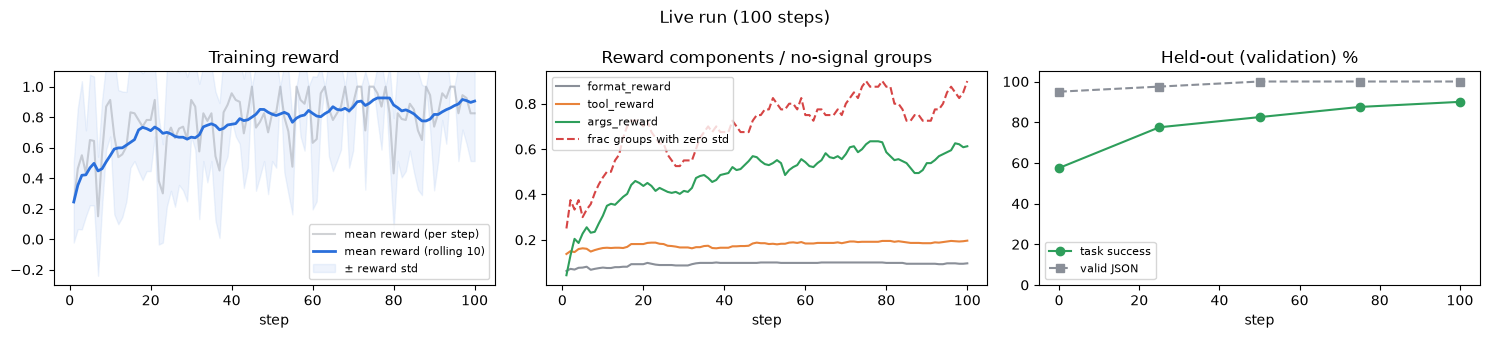

Mean training reward rose from 0.55 (first 10 steps) to 0.91 (last 10 steps).
Groups with zero reward std (no learning signal): 48% -> 90%.
Held-out task success: 57.5% at step 0 -> 90.0% at the end (best 90.0%).


In [18]:
from farm_grpo.plotting import plot_training, training_summary
plot_training(live_log, live_heldout, title=f"Live run ({LIVE_STEPS} steps)")
plt.show()
print(training_summary(live_log, live_heldout))

**What this plot shows (our Ukrainian dry run):** the mean training reward climbs from ~0.50 to ~0.86 within 100 steps, almost entirely through `args_reward` (format is saturated from the start).
The red dashed line rises from ~30 % to ~90 %: most groups end up "all correct", so the learning signal is used up.
Held-out (validation) success goes from 57.5 % to 90 %, but watch the test set in Section 7: it improves much less.

**Note:** training reward alone does *not* prove learning. Always look at the held-out curve.

---
# Section 7 · Evaluate the trained policy

Same 80 **test** prompts (unseen template families, unseen barn D / cameras 7–8), greedy decoding.

In [ ]:
results, dfs = {"Before GRPO": base_metrics}, {"Before GRPO": base_df}
m, tok = load_model(cfg.model_id, adapter_path=str(LIVE_DIR))
results["After GRPO"], dfs["After GRPO"] = evaluate(m, tok, records["test"], cfg.eval_batch_size, cfg.eval_max_new_tokens)
del m; torch.cuda.empty_cache()

table = compare(results)
table

In [ ]:
from farm_grpo.plotting import plot_comparison
plot_comparison(table);

**What this plot shows (our Ukrainian dry run):** valid JSON (95 %) and the correct tool (~81 %) barely change; the gain in task success, 37.5 % → 60 %, comes from **correct arguments**,
i.e. turning «сьогодні ввечері», «7.30» or «8 березня» into canonical values. The gap to validation (90 %) is the lesson: the worst test family, `mixer_distract2` («Камера 3 працює нормально…»), stays at 0 % because the model calls the camera tool, and `robot_distract2` even drops from 70 % to 50 %.

## 7.1 Error analysis

In [ ]:
best = "After GRPO"
print("Errors by type:", best)
display(error_breakdown(dfs[best]))

# Per template family: where does the model still fail?
by_family = pd.concat({k: d.groupby("family")["task_success"].mean().mul(100).round(0) for k, d in dfs.items()}, axis=1)
by_family

In [ ]:
# Prompts fixed by training and prompts broken by training
b, a = dfs["Before GRPO"].set_index("id"), dfs[best].set_index("id")
fixed = a[(~b.task_success) & a.task_success]
broken = a[b.task_success & (~a.task_success)]
print(f"fixed by GRPO: {len(fixed)}   broken by GRPO: {len(broken)}")
pd.concat([b.loc[fixed.index, ["question", "completion"]].rename(columns={"completion": "before"}),
           a.loc[fixed.index, ["completion"]].rename(columns={"completion": "after"})], axis=1).head(8)

In [ ]:
# Remaining failures after training
a[~a.task_success][["question", "expected_args", "completion", "error"]].head(10)

**Discuss:**
* Did the model *really* improve (correct arguments on unseen phrasings) or did it mostly learn the **format**?
* Which families still fail, and why? (day-part conventions? relative dates? time formats? distractors?)
* Would SFT on the 240 labelled examples have done as well?

---
# Section 8 · Challenge

## 8.1 Reward hacking

`src/farm_grpo/rewards_bad.py` contains rewards that *look* reasonable but are not task success:

| Bad reward | What it rewards | How it can be hacked |
|---|---|---|
| `format_only_reward` | Any JSON with a `"tool"` key | Correct format, wrong tool / args |
| `keyword_reward` | Correct tool **name** appears anywhere | Mention every tool name |
| `many_args_reward` | 0.25 per argument key ("detailed calls") | Stuff the arguments with extra keys |

Train with one of them, then measure with the **real** metrics. Training reward goes up. Does task success?
The background run (Section 0) used `many_args`. To try the others, set `TRAINING_MODE = "inline"` and change `HACK`.

In [ ]:
from farm_grpo.rewards_bad import BAD_REWARDS
HACK = "many_args"          # inline mode: try "format_only", "keyword", "many_args"
hack_dir = HACK_DIR if HACK == "many_args" else cfg.output_dir / f"hack_{HACK}"

if TRAINING_MODE == "background":
    wait_for(["hack"], lang=LANG)
elif TRAINING_MODE == "inline":
    trainer, _ = train_grpo(cfg, train_ds, BAD_REWARDS[HACK], hack_dir, max_steps=HACK_STEPS,
                            heldout_records=records["val"], heldout_every=max(HACK_STEPS // 3, 1),
                            learning_rate=5e-5)
    del trainer; torch.cuda.empty_cache()

hack_log = json.loads((hack_dir / "log_history.json").read_text())
hack_heldout = json.loads((hack_dir / "heldout_history.json").read_text())

plot_training(hack_log, hack_heldout, title=f"Bad reward: {HACK}")
plt.show()
print(training_summary(hack_log, hack_heldout))

**What this plot shows (our Ukrainian dry run):** the training reward climbs from ~0.56 to ~0.91 while held-out task success collapses from 57.5 % to 0 % (0 % on test as well).
The outputs are still valid JSON, but the arguments are stuffed with extra keys, so no call is executable. A rising reward curve proves nothing unless the reward *is* the task.

In [ ]:
m, tok = load_model(cfg.model_id, adapter_path=str(hack_dir))
results[f"Hacked ({HACK})"], dfs[f"Hacked ({HACK})"] = evaluate(m, tok, records["test"])
del m; torch.cuda.empty_cache()
display(compare(results))
dfs[f"Hacked ({HACK})"][["question", "completion", "error"]].head(8)

**Ideas to explore**
1. Change `HACK` and compare. Which bad reward is hacked fastest, and why?
2. Fix the bad reward *minimally* so it cannot be hacked. What did you need to add?
3. Use `reward_weights` in `GRPOConfig` (e.g. `train_grpo(..., reward_weights=[1.0, 0.0, 0.0])`) to train on format only. What happens to `frac_reward_zero_std`?

## 8.2 Multi-step investigation (transfer test)

Questions that need **both** the feeding schedule **and** the robot events, graded by **environment outcome** (was the final answer right?).
Our training was single-step, so does it transfer?

In [ ]:
from farm_grpo.agent import make_tasks, evaluate_agent
tasks = make_tasks(world, lang=LANG)
pd.DataFrame([{"question": t.question, **t.truth} for t in tasks])

In [ ]:
agent_results = {}
for name, path in [("Before GRPO", None), ("After GRPO", LIVE_DIR)]:
    m, tok = load_model(cfg.model_id, adapter_path=str(path) if path else None)
    agent_df, trajectories = evaluate_agent(m, tok, world, tasks)
    agent_results[name] = agent_df[["answer_correct", "used_required_tools", "success"]].mean().mul(100).round(0)
    print(f"\n################ {name} ################")
    for tr in trajectories[:2]:
        print(tr.pretty(), "\n")
    del m; torch.cuda.empty_cache()
agent_table = pd.DataFrame(agent_results)
agent_table

**Discuss / advanced extension**
* Did single-step GRPO help, hurt, or not matter for the multi-step agent? (Training only ever rewarded *one* JSON object.)
* Design an **outcome reward** for the multi-step task: reward 1 only if the final answer is right *and* the required tools were used.
* Current TRL supports tool-calling rollouts and environment-managed rewards (`GRPOTrainer(tools=..., environment_factory=...)`), which is the natural next stage.

---
# Section 9 · Metrics summary

All metrics of this notebook, reported separately per language and saved to `outputs/` (English) or `outputs/uk/` (Ukrainian):
`results.json` (test-set metrics per model), `results_by_family.csv` (task success per template family), `agent_results.json` (multi-step agent).

In [ ]:
cfg.output_dir.mkdir(parents=True, exist_ok=True)
(cfg.output_dir / "results.json").write_text(json.dumps(results, indent=1))
pd.concat({k: d.groupby("family")["task_success"].mean().mul(100).round(1) for k, d in dfs.items()},
          axis=1).to_csv(cfg.output_dir / "results_by_family.csv")
(cfg.output_dir / "agent_results.json").write_text(agent_table.to_json(indent=1))
print(f"[{LANG}] saved to {cfg.output_dir}")

print("\nTest set (80 prompts):")
display(compare(results))
print("Multi-step agent (4 questions):")
display(agent_table)

---
### Wrap-up
* RL lets us optimise **outcomes** we can score, without a perfect demonstration.
* GRPO: group sampling + relative advantages, no critic.
* The reward **is** the specification. Models optimise what you measure, not what you mean.
* Always check: signal (reward variance), held-out success, failure inspection.